# 医学影像经典分类基线：5 次训练、Top-2 模型保存与可解释性验证

本 Notebook 用同一份固定的 `train/val/test` 数据，比较 6 种经典算法：SVM、KNN、随机森林、决策树、Gaussian Naive Bayes 和逻辑回归。输入特征统一使用 HOG，以保证比较公平。

实验规则：

1. 每个算法使用 5 个随机种子运行；数据划分始终不变。
2. 模型排名只使用验证集 Balanced Accuracy，测试集不参与模型选择。
3. 每种算法只保留验证集排名最好的 2 个模型，但论文统计使用全部 5 次测试结果的均值 ± 样本标准差。
4. 经典算法没有卷积层，不能生成真正的 Grad-CAM；最后使用模型无关的 Occlusion Sensitivity（遮挡敏感性热图）检查模型关注区域。不要把它标成 Grad-CAM。

> 提醒：KNN、GaussianNB 等确定性算法在固定数据和固定特征下，5 次结果可能完全相同、标准差为 0。这是正常现象，不能人为扰动数据来制造差异。


## 阶段一：环境导入与实验配置

本阶段选择脑肿瘤或脑出血任务，并设置数据目录、随机种子、HOG 参数和结果保存目录。只需修改 `TASK`；正式实验不要重新划分 train/val/test。


In [1]:
# 如果环境缺少依赖，只需取消下一行注释并运行一次，然后重启本单元格。
# !pip install -q scikit-image scikit-learn joblib

from pathlib import Path
import hashlib
import json
import random
import shutil
import time
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from IPython.display import display

from skimage.feature import hog
from skimage.transform import resize

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
)

# 可选："tumor" 或 "hemorrhage"
TASK = "tumor"

TASK_CONFIG = {
    "tumor": {
        "name": "BrainTumor",
        "data_dir": Path("/root/autodl-tmp/medical_data/brain_tumor"),
    },
    "hemorrhage": {
        "name": "BrainHemorrhage",
        "data_dir": Path("/root/autodl-tmp/medical_data/brain_hemorrhage"),
    },
}

assert TASK in TASK_CONFIG, f"TASK 必须是 {list(TASK_CONFIG)}"

DATASET_NAME = TASK_CONFIG[TASK]["name"]
DATA_DIR = TASK_CONFIG[TASK]["data_dir"]
SEEDS = [1, 3, 7, 21, 42]

IMAGE_SIZE = (224, 224)
HOG_KWARGS = {
    "orientations": 9,
    "pixels_per_cell": (16, 16),
    "cells_per_block": (2, 2),
    "block_norm": "L2-Hys",
}

# 验证集模型排序指标。对类别不均衡任务，比普通 Accuracy 更稳妥。
SELECT_METRIC = "balanced_accuracy"
TOP_K_MODELS = 2
REBUILD_FEATURE_CACHE = False

RUN_ROOT = (
    Path("/root/autodl-tmp/classical_baseline_results")
    / DATASET_NAME
)
FEATURE_CACHE_DIR = RUN_ROOT / "feature_cache"
SAVED_MODEL_DIR = RUN_ROOT / "saved_models"
EXPLAIN_DIR = RUN_ROOT / "explanations"

for directory in (
    RUN_ROOT,
    FEATURE_CACHE_DIR,
    SAVED_MODEL_DIR,
    EXPLAIN_DIR,
):
    directory.mkdir(parents=True, exist_ok=True)

print("=" * 72)
print("经典算法医学影像分类实验")
print("=" * 72)
print("任务          :", TASK)
print("数据集        :", DATASET_NAME)
print("数据目录      :", DATA_DIR)
print("随机种子      :", SEEDS)
print("模型选择指标  : Validation", SELECT_METRIC)
print("输出目录      :", RUN_ROOT)
print("=" * 72)


经典算法医学影像分类实验
任务          : tumor
数据集        : BrainTumor
数据目录      : /root/autodl-tmp/medical_data/brain_tumor
随机种子      : [1, 3, 7, 21, 42]
模型选择指标  : Validation balanced_accuracy
输出目录      : /root/autodl-tmp/classical_baseline_results/BrainTumor


## 阶段二：检查数据目录、类别映射与跨集合重复图片

本阶段只读取数据，不修改任何图片。目录必须是 `train/val/test`，每个集合下必须包含 `negative/positive`。同时检查完全相同的文件是否跨集合出现；若发现重叠，应先修复数据泄漏再训练。


In [2]:
VALID_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}
CLASS_TO_IDX = {"negative": 0, "positive": 1}


def collect_samples(split):
    samples = []
    split_dir = DATA_DIR / split

    if not split_dir.exists():
        raise FileNotFoundError(f"找不到目录：{split_dir}")

    for class_name, label in CLASS_TO_IDX.items():
        class_dir = split_dir / class_name

        if not class_dir.exists():
            raise FileNotFoundError(f"找不到类别目录：{class_dir}")

        paths = sorted(
            path for path in class_dir.rglob("*")
            if path.is_file() and path.suffix.lower() in VALID_EXTENSIONS
        )

        if not paths:
            raise RuntimeError(f"类别目录没有图片：{class_dir}")

        samples.extend((path, label) for path in paths)

    return samples


samples_by_split = {
    split: collect_samples(split)
    for split in ("train", "val", "test")
}

count_rows = []
for split, samples in samples_by_split.items():
    for class_name, label in CLASS_TO_IDX.items():
        count_rows.append({
            "split": split,
            "class": class_name,
            "count": sum(y == label for _, y in samples),
        })

display(pd.DataFrame(count_rows).pivot(index="split", columns="class", values="count"))


def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, "rb") as file:
        for chunk in iter(lambda: file.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


hashes_by_split = {
    split: {sha256_file(path): str(path) for path, _ in samples}
    for split, samples in samples_by_split.items()
}

overlap_rows = []
for left, right in (("train", "val"), ("train", "test"), ("val", "test")):
    overlap = set(hashes_by_split[left]) & set(hashes_by_split[right])
    overlap_rows.append({"pair": f"{left}-{right}", "exact_duplicates": len(overlap)})

overlap_df = pd.DataFrame(overlap_rows)
display(overlap_df)

if overlap_df["exact_duplicates"].sum() > 0:
    raise RuntimeError("发现跨集合完全重复图片。请先排除数据泄漏，再运行训练。")

print("✓ 目录结构、类别映射和精确重复检查通过")


class,negative,positive
split,,
test,225,225
train,1050,1050
val,225,225


,pair,exact_duplicates
0,train-val,0
1,train-test,0
2,val-test,0


✓ 目录结构、类别映射和精确重复检查通过


## 阶段三：提取并缓存 HOG 特征

本阶段把每张图统一转为灰度、缩放到 224×224，再提取 HOG 纹理与边缘特征。所有经典算法使用完全相同的特征。特征会缓存到磁盘，后续重复运行无需再次提取；图片内容变化后应设置 `REBUILD_FEATURE_CACHE=True`。


In [3]:
def load_gray_image(path):
    with Image.open(path) as image:
        image = image.convert("L").resize(IMAGE_SIZE, Image.Resampling.BILINEAR)
        return np.asarray(image, dtype=np.float32) / 255.0


def extract_hog_dataset(samples, split):
    cache_path = FEATURE_CACHE_DIR / f"{split}_hog.npz"

    if cache_path.exists() and not REBUILD_FEATURE_CACHE:
        cached = np.load(cache_path, allow_pickle=False)
        print(f"✓ 从缓存读取 {split}: {cache_path}")
        return cached["X"], cached["y"], cached["paths"].astype(str)

    features, labels, paths = [], [], []
    total = len(samples)
    start = time.time()

    for index, (path, label) in enumerate(samples, start=1):
        gray = load_gray_image(path)
        feature = hog(gray, feature_vector=True, **HOG_KWARGS)
        features.append(feature.astype(np.float32))
        labels.append(label)
        paths.append(str(path))

        if index == 1 or index % 100 == 0 or index == total:
            print(f"{split:5s}: {index:5d}/{total:5d}")

    X = np.stack(features)
    y = np.asarray(labels, dtype=np.int64)
    paths = np.asarray(paths)
    np.savez_compressed(cache_path, X=X, y=y, paths=paths)
    print(f"✓ {split} 特征完成：{X.shape}，耗时 {(time.time() - start) / 60:.2f} 分钟")
    return X, y, paths


X_train, y_train, train_paths = extract_hog_dataset(samples_by_split["train"], "train")
X_val, y_val, val_paths = extract_hog_dataset(samples_by_split["val"], "val")
X_test, y_test, test_paths = extract_hog_dataset(samples_by_split["test"], "test")

print("\n特征维度：", X_train.shape[1])
print("Train / Val / Test：", len(y_train), len(y_val), len(y_test))


train:     1/ 2100
train:   100/ 2100
train:   200/ 2100
train:   300/ 2100
train:   400/ 2100
train:   500/ 2100
train:   600/ 2100
train:   700/ 2100
train:   800/ 2100
train:   900/ 2100
train:  1000/ 2100
train:  1100/ 2100
train:  1200/ 2100
train:  1300/ 2100
train:  1400/ 2100
train:  1500/ 2100
train:  1600/ 2100
train:  1700/ 2100
train:  1800/ 2100
train:  1900/ 2100
train:  2000/ 2100
train:  2100/ 2100
✓ train 特征完成：(2100, 6084)，耗时 0.32 分钟
val  :     1/  450
val  :   100/  450
val  :   200/  450
val  :   300/  450
val  :   400/  450
val  :   450/  450
✓ val 特征完成：(450, 6084)，耗时 0.06 分钟
test :     1/  450
test :   100/  450
test :   200/  450
test :   300/  450
test :   400/  450
test :   450/  450
✓ test 特征完成：(450, 6084)，耗时 0.05 分钟

特征维度： 6084
Train / Val / Test： 2100 450 450


## 阶段四：定义 6 种经典算法与评价指标

本阶段仅定义模型，不开始训练。标准化只放在需要距离或线性优化的模型管线里，防止验证集/测试集信息泄漏到特征缩放。Sensitivity 默认把 `positive` 当作阳性类。


In [4]:
def build_models(seed):
    return {
        "SVM": Pipeline([
            ("scale", StandardScaler()),
            ("model", SVC(
                C=1.0,
                kernel="rbf",
                probability=True,
                class_weight="balanced",
                random_state=seed,
            )),
        ]),
        "KNN": Pipeline([
            ("scale", StandardScaler()),
            ("model", KNeighborsClassifier(
                n_neighbors=5,
                weights="distance",
                metric="minkowski",
                p=2,
            )),
        ]),
        "RandomForest": RandomForestClassifier(
            n_estimators=300,
            class_weight="balanced",
            random_state=seed,
            n_jobs=-1,
        ),
        "DecisionTree": DecisionTreeClassifier(
            class_weight="balanced",
            random_state=seed,
        ),
        "GaussianNB": GaussianNB(
            var_smoothing=1e-9
        ),
        "LogisticRegression": Pipeline([
            ("scale", StandardScaler()),
            ("model", LogisticRegression(
                solver="saga",
                C=1.0,
                max_iter=3000,
                class_weight="balanced",
                random_state=seed,
                n_jobs=-1,
            )),
        ]),
    }


def positive_scores(model, X):
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:, 1]
    scores = model.decision_function(X)
    return 1.0 / (1.0 + np.exp(-scores))


def calculate_metrics(model, X, y):
    pred = model.predict(X)
    score = positive_scores(model, X)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    specificity = tn / (tn + fp) if (tn + fp) else np.nan

    try:
        roc_auc = roc_auc_score(y, score)
    except ValueError:
        roc_auc = np.nan

    try:
        pr_auc = average_precision_score(y, score)
    except ValueError:
        pr_auc = np.nan

    return {
        "accuracy": 100 * accuracy_score(y, pred),
        "balanced_accuracy": 100 * balanced_accuracy_score(y, pred),
        "sensitivity": 100 * recall_score(y, pred, zero_division=0),
        "specificity": 100 * specificity,
        "precision": 100 * precision_score(y, pred, zero_division=0),
        "f1": 100 * f1_score(y, pred, zero_division=0),
        "roc_auc": 100 * roc_auc,
        "pr_auc": 100 * pr_auc,
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
    }


MODEL_NAMES = list(build_models(SEEDS[0]))
print("将运行的模型：", MODEL_NAMES)


将运行的模型： ['SVM', 'KNN', 'RandomForest', 'DecisionTree', 'GaussianNB', 'LogisticRegression']


## 阶段五：每种算法运行 5 次，并在训练过程中直接覆盖 Top-2

每种算法只维护 `rank_1.joblib` 和 `rank_2.joblib` 两个固定文件。每次训练结束后仅根据验证集 Balanced Accuracy、ROC-AUC 和 F1 排名：如果新模型进入前两名，就立即覆盖对应名次；未进入前两名的模型不会写入磁盘。测试集不参与覆盖判断。经典算法没有 epoch，因此不报告“最佳 epoch”。


In [5]:
def ranking_key(val_metrics, seed):
    # 数值越大排名越靠前；完全并列时较小 seed 优先，保证可复现。
    return (
        float(val_metrics["balanced_accuracy"]),
        float(val_metrics["roc_auc"]),
        float(val_metrics["f1"]),
        -int(seed),
    )


all_rows = []
selected_top2_rows = []

# 仅重置本 Notebook 专属的最终模型目录，避免上一次运行残留。
if SAVED_MODEL_DIR.exists():
    shutil.rmtree(SAVED_MODEL_DIR)
SAVED_MODEL_DIR.mkdir(parents=True, exist_ok=True)

for model_name in MODEL_NAMES:
    model_save_dir = SAVED_MODEL_DIR / model_name
    model_save_dir.mkdir(parents=True, exist_ok=True)
    top_two = []

    for run_index, seed in enumerate(SEEDS, start=1):
        print("\n" + "=" * 78)
        print(f"模型：{model_name} | 第 {run_index}/{len(SEEDS)} 次 | seed={seed}")
        print("=" * 78)

        random.seed(seed)
        np.random.seed(seed)
        model = build_models(seed)[model_name]

        start = time.time()
        with warnings.catch_warnings(record=True) as caught_warnings:
            warnings.simplefilter("always")
            model.fit(X_train, y_train)
        fit_seconds = time.time() - start

        for warning in caught_warnings:
            print("训练警告：", warning.message)

        val_metrics = calculate_metrics(model, X_val, y_val)
        test_metrics = calculate_metrics(model, X_test, y_test)

        row = {
            "model": model_name,
            "seed": seed,
            "fit_seconds": fit_seconds,
        }
        row.update({f"val_{key}": value for key, value in val_metrics.items()})
        row.update({f"test_{key}": value for key, value in test_metrics.items()})
        all_rows.append(row)

        bundle = {
            "model": model,
            "model_name": model_name,
            "seed": seed,
            "dataset_name": DATASET_NAME,
            "class_to_idx": CLASS_TO_IDX,
            "image_size": IMAGE_SIZE,
            "hog_kwargs": HOG_KWARGS,
            "selection_metric": SELECT_METRIC,
            "val_metrics": val_metrics,
            "test_metrics": test_metrics,
        }

        candidate = {
            "key": ranking_key(val_metrics, seed),
            "bundle": bundle,
            "row": row,
        }

        previous_seeds = [item["bundle"]["seed"] for item in top_two]
        top_two.append(candidate)
        top_two.sort(key=lambda item: item["key"], reverse=True)
        top_two = top_two[:TOP_K_MODELS]
        current_seeds = [item["bundle"]["seed"] for item in top_two]

        if current_seeds != previous_seeds:
            # 文件名固定，因此出现更优模型时会直接覆盖旧的 rank_1/rank_2。
            for rank, item in enumerate(top_two, start=1):
                save_path = model_save_dir / f"rank_{rank}.joblib"
                joblib.dump(item["bundle"], save_path, compress=3)

            # 第一轮还没有 rank_2；若目录内存在旧文件则移除，避免误读。
            if len(top_two) < TOP_K_MODELS:
                stale_rank2 = model_save_dir / "rank_2.joblib"
                if stale_rank2.exists():
                    stale_rank2.unlink()

            print("✓ Top-2 已更新并覆盖：", current_seeds)
        else:
            print("- 本次未进入验证集 Top-2，不保存模型")

        print(f"Validation Balanced Acc : {val_metrics['balanced_accuracy']:.2f}%")
        print(f"Validation F1           : {val_metrics['f1']:.2f}%")
        print(f"Test Accuracy           : {test_metrics['accuracy']:.2f}%")
        print(f"Test Balanced Acc       : {test_metrics['balanced_accuracy']:.2f}%")
        print(f"Test Sens/Spec          : {test_metrics['sensitivity']:.2f}% / {test_metrics['specificity']:.2f}%")
        print(f"Test F1 / ROC-AUC       : {test_metrics['f1']:.2f}% / {test_metrics['roc_auc']:.2f}%")

    # 记录本算法最终保留下来的两个固定文件。
    for rank, item in enumerate(top_two, start=1):
        selected = dict(item["row"])
        selected["rank"] = rank
        selected["saved_model_path"] = str(model_save_dir / f"rank_{rank}.joblib")
        selected_top2_rows.append(selected)

results_df = pd.DataFrame(all_rows)
selected_top2_df = pd.DataFrame(selected_top2_rows)

results_df.to_csv(RUN_ROOT / "all_5run_results.csv", index=False)
selected_top2_df.to_csv(RUN_ROOT / "selected_top2_models.csv", index=False)

print("\n✓ 所有训练完成；磁盘中每种算法最多只有两个模型文件")
display(results_df[[
    "model", "seed", "val_balanced_accuracy", "val_f1",
    "test_accuracy", "test_balanced_accuracy", "test_sensitivity",
    "test_specificity", "test_f1", "test_roc_auc", "test_pr_auc",
]])



模型：SVM | 第 1/5 次 | seed=1
✓ Top-2 已更新并覆盖： [1]
Validation Balanced Acc : 98.22%
Validation F1           : 98.23%
Test Accuracy           : 97.78%
Test Balanced Acc       : 97.78%
Test Sens/Spec          : 99.11% / 96.44%
Test F1 / ROC-AUC       : 97.81% / 99.90%

模型：SVM | 第 2/5 次 | seed=3
✓ Top-2 已更新并覆盖： [1, 3]
Validation Balanced Acc : 98.22%
Validation F1           : 98.23%
Test Accuracy           : 97.78%
Test Balanced Acc       : 97.78%
Test Sens/Spec          : 99.11% / 96.44%
Test F1 / ROC-AUC       : 97.81% / 99.90%

模型：SVM | 第 3/5 次 | seed=7
- 本次未进入验证集 Top-2，不保存模型
Validation Balanced Acc : 98.22%
Validation F1           : 98.23%
Test Accuracy           : 97.78%
Test Balanced Acc       : 97.78%
Test Sens/Spec          : 99.11% / 96.44%
Test F1 / ROC-AUC       : 97.81% / 99.90%

模型：SVM | 第 4/5 次 | seed=21
- 本次未进入验证集 Top-2，不保存模型
Validation Balanced Acc : 98.22%
Validation F1           : 98.23%
Test Accuracy           : 97.78%
Test Balanced Acc       : 97.78%
Test Sens/Spec        

,model,seed,val_balanced_accuracy,val_f1,test_accuracy,test_balanced_accuracy,test_sensitivity,test_specificity,test_f1,test_roc_auc,test_pr_auc
0,SVM,1,98.222222,98.230088,97.777778,97.777778,99.111111,96.444444,97.807018,99.895309,99.903425
1,SVM,3,98.222222,98.230088,97.777778,97.777778,99.111111,96.444444,97.807018,99.895309,99.903425
2,SVM,7,98.222222,98.230088,97.777778,97.777778,99.111111,96.444444,97.807018,99.895309,99.903425
3,SVM,21,98.222222,98.230088,97.777778,97.777778,99.111111,96.444444,97.807018,99.895309,99.903425
4,SVM,42,98.222222,98.230088,97.777778,97.777778,99.111111,96.444444,97.807018,99.895309,99.903425
5,KNN,1,97.333333,97.345133,98.444444,98.444444,98.222222,98.666667,98.440980,99.182222,98.721475
6,KNN,3,97.333333,97.345133,98.444444,98.444444,98.222222,98.666667,98.440980,99.182222,98.721475
7,KNN,7,97.333333,97.345133,98.444444,98.444444,98.222222,98.666667,98.440980,99.182222,98.721475
8,KNN,21,97.333333,97.345133,98.444444,98.444444,98.222222,98.666667,98.440980,99.182222,98.721475
9,KNN,42,97.333333,97.345133,98.444444,98.444444,98.222222,98.666667,98.440980,99.182222,98.721475


## 阶段六：核对最终保留的两个模型

这一阶段不再复制或删除模型，只显示阶段五动态覆盖后最终留下的 Top-2。每个算法目录中最多只有 `rank_1.joblib` 和 `rank_2.joblib`；排名完全由验证集决定。


In [6]:
print("=" * 88)
print("每种算法最终保留的 Top-2 模型（仅按验证集选择）")
print("=" * 88)

display(selected_top2_df[[
    "model", "rank", "seed", "val_balanced_accuracy", "val_roc_auc",
    "val_f1", "test_accuracy", "test_balanced_accuracy", "saved_model_path",
]])

print("\n实际模型文件：")
for path in sorted(SAVED_MODEL_DIR.rglob("*.joblib")):
    print("-", path)


每种算法最终保留的 Top-2 模型（仅按验证集选择）


,model,rank,seed,val_balanced_accuracy,val_roc_auc,val_f1,test_accuracy,test_balanced_accuracy,saved_model_path
0,SVM,1,1,98.222222,99.926914,98.230088,97.777778,97.777778,/root/autodl-tmp/classical_baseline_results/Br...
1,SVM,2,3,98.222222,99.926914,98.230088,97.777778,97.777778,/root/autodl-tmp/classical_baseline_results/Br...
2,KNN,1,1,97.333333,99.615802,97.345133,98.444444,98.444444,/root/autodl-tmp/classical_baseline_results/Br...
3,KNN,2,3,97.333333,99.615802,97.345133,98.444444,98.444444,/root/autodl-tmp/classical_baseline_results/Br...
4,RandomForest,1,3,96.666667,99.573333,96.659243,95.777778,95.777778,/root/autodl-tmp/classical_baseline_results/Br...
5,RandomForest,2,42,96.666667,99.529877,96.703297,94.666667,94.666667,/root/autodl-tmp/classical_baseline_results/Br...
6,DecisionTree,1,42,88.666667,88.666667,88.741722,84.888889,84.888889,/root/autodl-tmp/classical_baseline_results/Br...
7,DecisionTree,2,7,88.444444,88.444444,88.392857,84.222222,84.222222,/root/autodl-tmp/classical_baseline_results/Br...
8,GaussianNB,1,1,76.888889,78.810864,78.861789,77.333333,77.333333,/root/autodl-tmp/classical_baseline_results/Br...
9,GaussianNB,2,3,76.888889,78.810864,78.861789,77.333333,77.333333,/root/autodl-tmp/classical_baseline_results/Br...



实际模型文件：
- /root/autodl-tmp/classical_baseline_results/BrainTumor/saved_models/DecisionTree/rank_1.joblib
- /root/autodl-tmp/classical_baseline_results/BrainTumor/saved_models/DecisionTree/rank_2.joblib
- /root/autodl-tmp/classical_baseline_results/BrainTumor/saved_models/GaussianNB/rank_1.joblib
- /root/autodl-tmp/classical_baseline_results/BrainTumor/saved_models/GaussianNB/rank_2.joblib
- /root/autodl-tmp/classical_baseline_results/BrainTumor/saved_models/KNN/rank_1.joblib
- /root/autodl-tmp/classical_baseline_results/BrainTumor/saved_models/KNN/rank_2.joblib
- /root/autodl-tmp/classical_baseline_results/BrainTumor/saved_models/LogisticRegression/rank_1.joblib
- /root/autodl-tmp/classical_baseline_results/BrainTumor/saved_models/LogisticRegression/rank_2.joblib
- /root/autodl-tmp/classical_baseline_results/BrainTumor/saved_models/RandomForest/rank_1.joblib
- /root/autodl-tmp/classical_baseline_results/BrainTumor/saved_models/RandomForest/rank_2.joblib
- /root/autodl-tmp/classical_ba

## 阶段七：汇总全部 5 次测试结果的均值与标准差

这张表才适合用于论文中的主要定量比较。Top-2 模型只是为了保存和后续解释，不能只用 Top-2 的测试结果宣称算法性能，否则会产生选择偏差。


In [7]:
REPORT_METRICS = [
    "test_accuracy",
    "test_balanced_accuracy",
    "test_sensitivity",
    "test_specificity",
    "test_precision",
    "test_f1",
    "test_roc_auc",
    "test_pr_auc",
]

summary_rows = []
for model_name, group in results_df.groupby("model", sort=False):
    summary = {"model": model_name, "runs": len(group)}

    for metric in REPORT_METRICS:
        values = group[metric].astype(float)
        short_name = metric.removeprefix("test_")
        mean_value = values.mean()
        std_value = values.std(ddof=1)
        summary[f"{short_name}_mean"] = mean_value
        summary[f"{short_name}_std"] = std_value
        summary[f"{short_name}_mean_std"] = f"{mean_value:.2f} ± {std_value:.2f}"

    summary_rows.append(summary)

summary_df = pd.DataFrame(summary_rows)
summary_df.to_csv(RUN_ROOT / "summary_all_5runs_mean_std.csv", index=False)

display_columns = ["model", "runs"] + [
    f"{metric.removeprefix('test_')}_mean_std"
    for metric in REPORT_METRICS
]

print("=" * 100)
print("全部 5 次测试结果：Mean ± Sample SD")
print("=" * 100)
display(summary_df[display_columns])

print("结果文件：")
print("-", RUN_ROOT / "all_5run_results.csv")
print("-", RUN_ROOT / "selected_top2_models.csv")
print("-", RUN_ROOT / "summary_all_5runs_mean_std.csv")
print("-", SAVED_MODEL_DIR)


全部 5 次测试结果：Mean ± Sample SD


,model,runs,accuracy_mean_std,balanced_accuracy_mean_std,sensitivity_mean_std,specificity_mean_std,precision_mean_std,f1_mean_std,roc_auc_mean_std,pr_auc_mean_std
0,SVM,5,97.78 ± 0.00,97.78 ± 0.00,99.11 ± 0.00,96.44 ± 0.00,96.54 ± 0.00,97.81 ± 0.00,99.90 ± 0.00,99.90 ± 0.00
1,KNN,5,98.44 ± 0.00,98.44 ± 0.00,98.22 ± 0.00,98.67 ± 0.00,98.66 ± 0.00,98.44 ± 0.00,99.18 ± 0.00,98.72 ± 0.00
2,RandomForest,5,95.42 ± 0.46,95.42 ± 0.46,97.78 ± 0.31,93.07 ± 0.92,93.38 ± 0.81,95.53 ± 0.43,99.05 ± 0.06,99.09 ± 0.06
3,DecisionTree,5,84.22 ± 0.50,84.22 ± 0.50,81.16 ± 0.67,87.29 ± 1.43,86.48 ± 1.24,83.73 ± 0.39,84.22 ± 0.50,79.60 ± 0.84
4,GaussianNB,5,77.33 ± 0.00,77.33 ± 0.00,86.22 ± 0.00,68.44 ± 0.00,73.21 ± 0.00,79.18 ± 0.00,79.20 ± 0.00,71.63 ± 0.00
5,LogisticRegression,5,97.82 ± 0.10,97.82 ± 0.10,98.31 ± 0.20,97.33 ± 0.00,97.36 ± 0.01,97.83 ± 0.10,99.19 ± 0.01,98.79 ± 0.01


结果文件：
- /root/autodl-tmp/classical_baseline_results/BrainTumor/all_5run_results.csv
- /root/autodl-tmp/classical_baseline_results/BrainTumor/selected_top2_models.csv
- /root/autodl-tmp/classical_baseline_results/BrainTumor/summary_all_5runs_mean_std.csv
- /root/autodl-tmp/classical_baseline_results/BrainTumor/saved_models


## 阶段八：为经典模型生成“CAM 式”遮挡敏感性热图

Grad-CAM 依赖卷积神经网络的特征图和梯度，SVM/KNN/随机森林等没有这些结构，因此不能套用之前的 Grad-CAM 类。这里使用 Occlusion Sensitivity：依次遮挡图像小区域，若某一区域被遮挡后模型对原预测类别的置信度明显下降，该区域会显示为红色。

它可以与 StableNet 的 Grad-CAM并列作为定性解释，但图题和论文中必须准确写成“Occlusion Sensitivity”，不能写成 Grad-CAM。


In [8]:
CAM_SEED = 42
IMAGES_PER_CLASS = 2
OCCLUSION_PATCH = 40
OCCLUSION_STRIDE = 24


def choose_explanation_images():
    rng = np.random.default_rng(CAM_SEED)
    selected = []

    for class_name, label in CLASS_TO_IDX.items():
        candidates = [Path(path) for path, y in samples_by_split["test"] if y == label]
        count = min(IMAGES_PER_CLASS, len(candidates))
        indices = rng.choice(len(candidates), size=count, replace=False)
        selected.extend(candidates[index] for index in indices)

    return selected


def feature_from_gray(gray):
    return hog(gray, feature_vector=True, **HOG_KWARGS).astype(np.float32)


def class_probability(model, X, target_class):
    probabilities = model.predict_proba(X)
    return probabilities[:, target_class]


def occlusion_sensitivity(model, gray, patch=40, stride=24):
    base_feature = feature_from_gray(gray)[None, :]
    base_probabilities = model.predict_proba(base_feature)[0]
    predicted_class = int(np.argmax(base_probabilities))
    baseline = float(base_probabilities[predicted_class])

    height, width = gray.shape
    y_positions = list(range(0, height - patch + 1, stride))
    x_positions = list(range(0, width - patch + 1, stride))
    if y_positions[-1] != height - patch:
        y_positions.append(height - patch)
    if x_positions[-1] != width - patch:
        x_positions.append(width - patch)

    occluded_features = []
    locations = []
    fill_value = float(np.median(gray))

    for y0 in y_positions:
        for x0 in x_positions:
            occluded = gray.copy()
            occluded[y0:y0 + patch, x0:x0 + patch] = fill_value
            occluded_features.append(feature_from_gray(occluded))
            locations.append((y0, x0))

    occluded_features = np.stack(occluded_features)
    occluded_scores = class_probability(model, occluded_features, predicted_class)

    heat_sum = np.zeros_like(gray, dtype=np.float32)
    heat_count = np.zeros_like(gray, dtype=np.float32)

    for (y0, x0), occluded_score in zip(locations, occluded_scores):
        importance = max(0.0, baseline - float(occluded_score))
        heat_sum[y0:y0 + patch, x0:x0 + patch] += importance
        heat_count[y0:y0 + patch, x0:x0 + patch] += 1

    heatmap = heat_sum / np.maximum(heat_count, 1)
    if heatmap.max() > 0:
        heatmap = heatmap / heatmap.max()

    return heatmap, predicted_class, baseline


best_model_rows = (
    selected_top2_df[selected_top2_df["rank"] == 1]
    .set_index("model")
)

best_models = {
    model_name: joblib.load(best_model_rows.loc[model_name, "saved_model_path"])["model"]
    for model_name in MODEL_NAMES
}

explanation_paths = choose_explanation_images()
print("固定用于解释的测试图片：")
for path in explanation_paths:
    print("-", path)


固定用于解释的测试图片：
- /root/autodl-tmp/medical_data/brain_tumor/test/negative/no1104.jpg
- /root/autodl-tmp/medical_data/brain_tumor/test/negative/no673.jpg
- /root/autodl-tmp/medical_data/brain_tumor/test/positive/y265.jpg
- /root/autodl-tmp/medical_data/brain_tumor/test/positive/y262.jpg


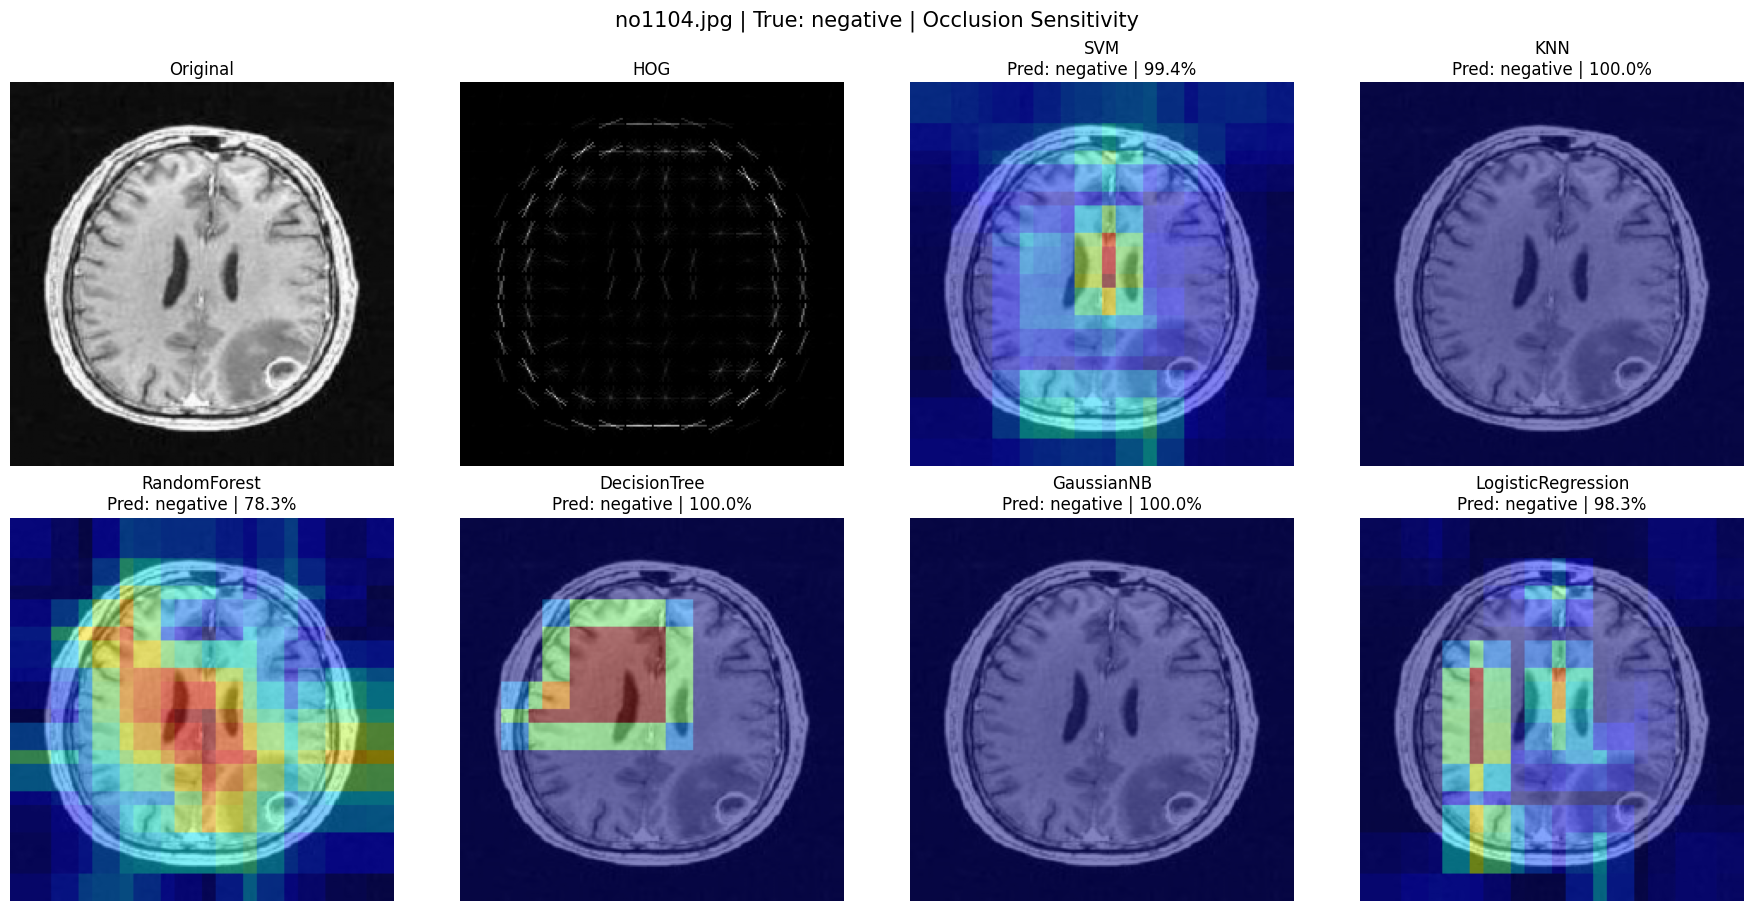

已保存： /root/autodl-tmp/classical_baseline_results/BrainTumor/explanations/no1104_occlusion.png


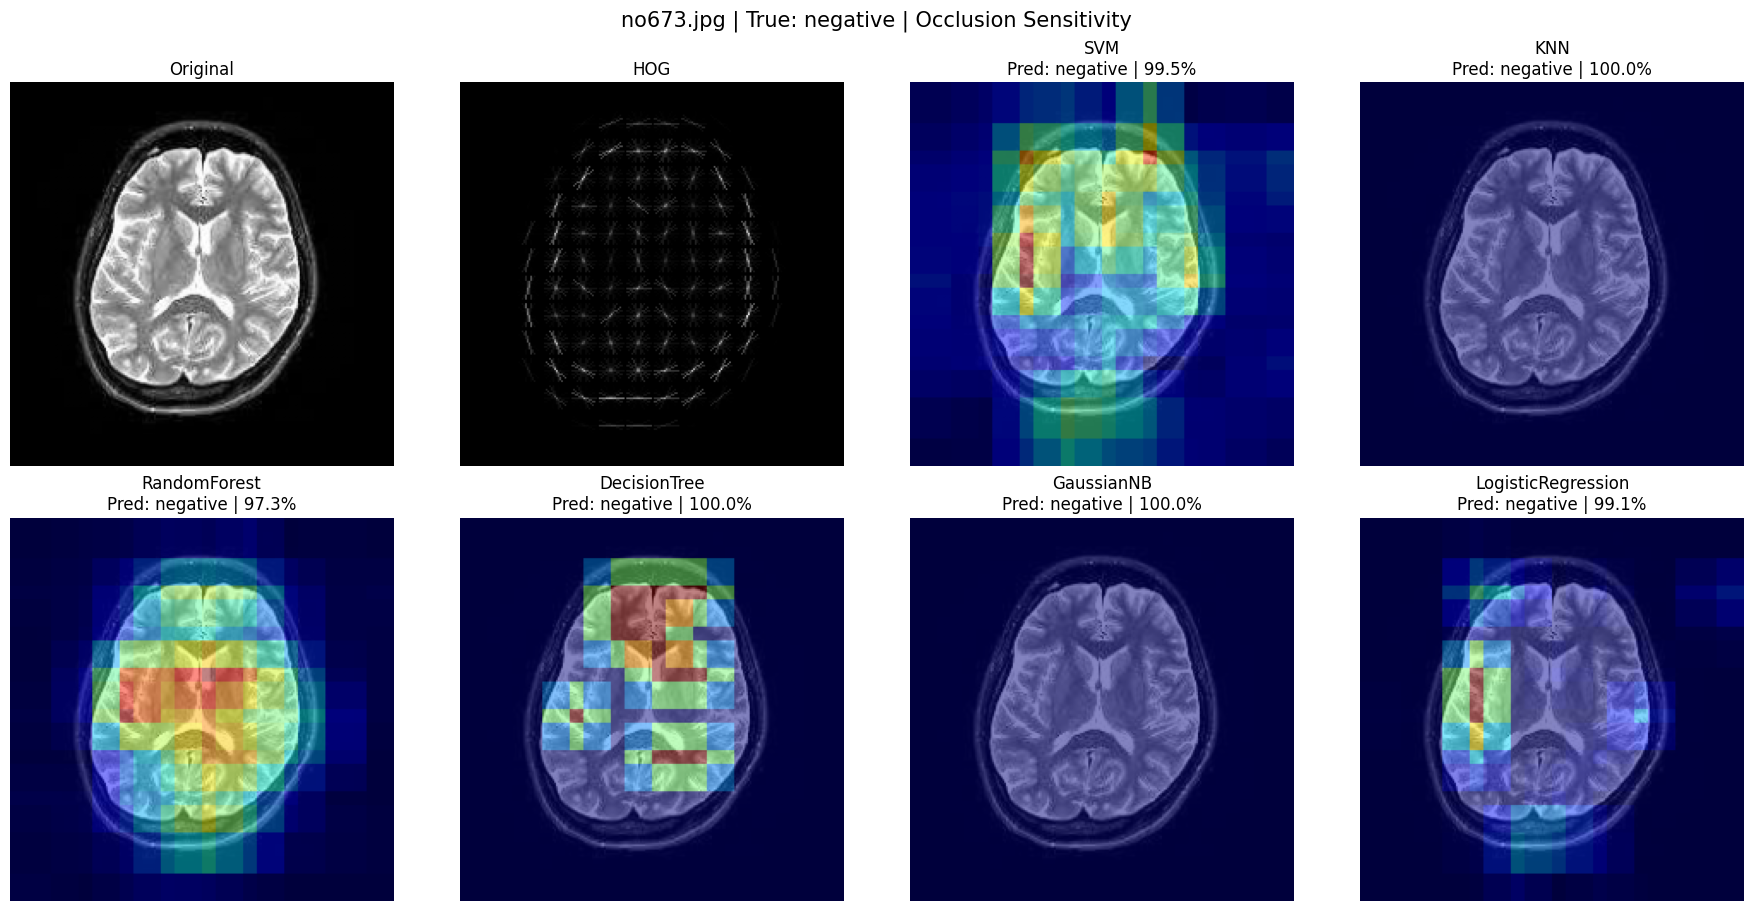

已保存： /root/autodl-tmp/classical_baseline_results/BrainTumor/explanations/no673_occlusion.png


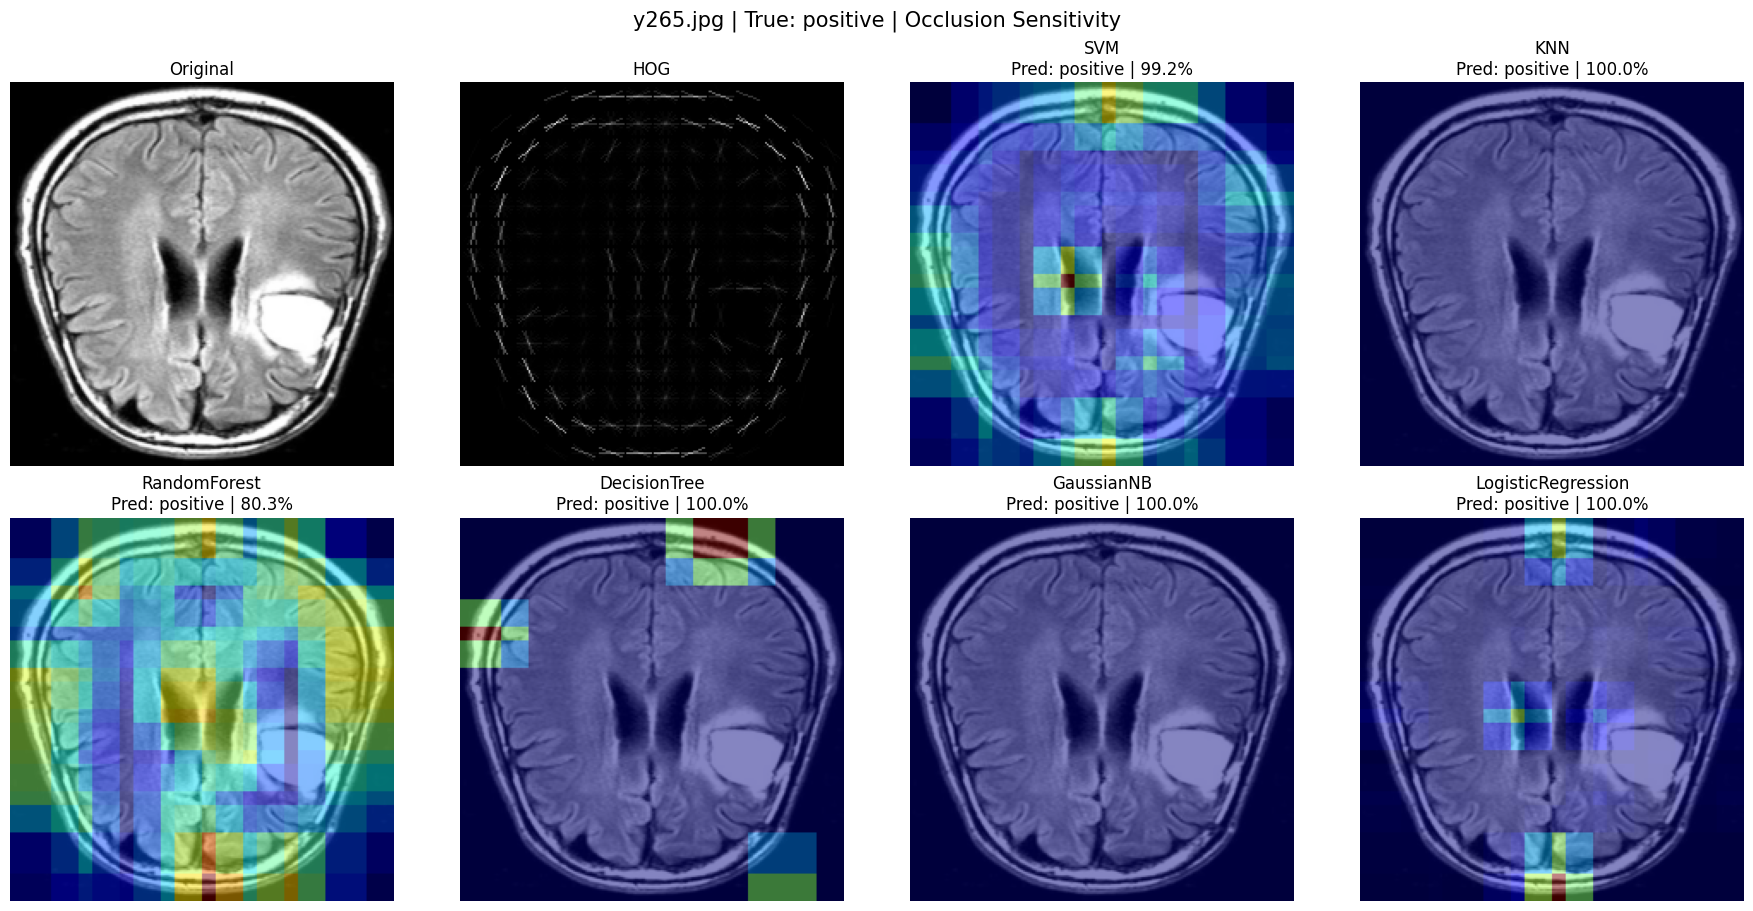

已保存： /root/autodl-tmp/classical_baseline_results/BrainTumor/explanations/y265_occlusion.png


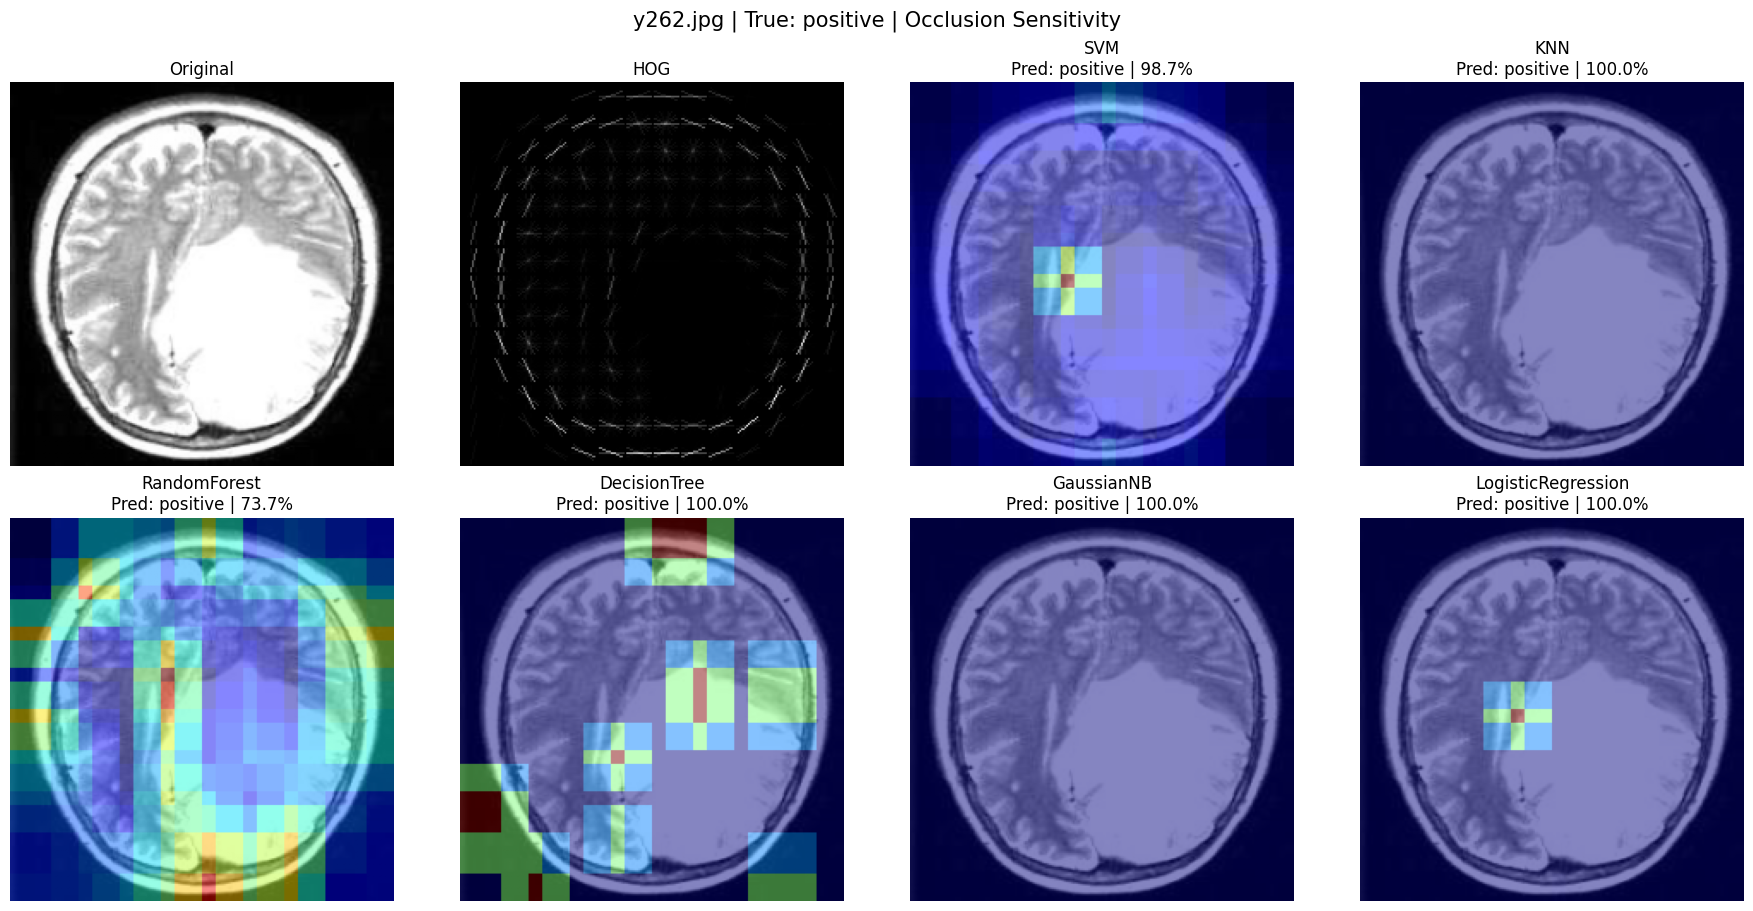

已保存： /root/autodl-tmp/classical_baseline_results/BrainTumor/explanations/y262_occlusion.png


In [9]:
CLASS_NAMES = {0: "negative", 1: "positive"}

for image_path in explanation_paths:
    gray = load_gray_image(image_path)
    _, hog_image = hog(gray, visualize=True, feature_vector=True, **HOG_KWARGS)

    panels = [("Original", gray, None), ("HOG", hog_image, None)]

    for model_name in MODEL_NAMES:
        heatmap, predicted_class, confidence = occlusion_sensitivity(
            best_models[model_name],
            gray,
            patch=OCCLUSION_PATCH,
            stride=OCCLUSION_STRIDE,
        )
        title = (
            f"{model_name}\n"
            f"Pred: {CLASS_NAMES[predicted_class]} | {confidence:.1%}"
        )
        panels.append((title, gray, heatmap))

    figure, axes = plt.subplots(2, 4, figsize=(18, 9), constrained_layout=True)

    for axis, (title, background, heatmap) in zip(axes.ravel(), panels):
        axis.imshow(background, cmap="gray")
        if heatmap is not None:
            axis.imshow(heatmap, cmap="jet", alpha=0.48, vmin=0, vmax=1)
        axis.set_title(title)
        axis.axis("off")

    true_class = image_path.parent.name
    figure.suptitle(
        f"{image_path.name} | True: {true_class} | Occlusion Sensitivity",
        fontsize=15,
    )

    save_path = EXPLAIN_DIR / f"{image_path.stem}_occlusion.png"
    figure.savefig(save_path, dpi=180, bbox_inches="tight")
    plt.show()
    print("已保存：", save_path)


## 阶段九：结果解释与论文使用注意事项

- 主要性能表使用阶段七中全部 5 次的 `Mean ± Sample SD`，不要只报告 Top-2。
- Top-2 是依据验证集选择并保存的模型，适合做复核、部署候选和可解释性展示。
- 红色区域表示遮挡后模型对原预测类别的置信度下降较多，即模型较依赖该区域；它不等价于病灶分割。
- 若热区长期位于边框、颅骨、文字、水印或黑色背景，说明经典模型可能利用了数据来源差异，而不是病灶。
- 若 KNN/GaussianNB 的 5 次结果完全一致，这是固定数据与确定性训练导致的正常结果。
- 比较 StableNet 时，必须使用相同 train/val/test、相同阳性定义和相同评价指标；经典算法的图称 Occlusion Sensitivity，StableNet 的图才称 Grad-CAM。
